# 01 · Data audit & EDA: BankSight

**Goal of this notebook:** load the CFPB sample into a local DuckDB warehouse, check its quality,
understand the outcome column, and propose a **target definition** and a **time-based train/validation/test split**.

In [1]:
from pathlib import Path
import json

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

**What this does:** works out where the project files live and checks that the input parquet file exists.
A *parquet* file is a compact column-based data file. The notebook sits in `notebooks/`, so the project root is one folder up.

In [2]:
if Path.cwd().name == "notebooks":
    ROOT = Path("..")
else:
    ROOT = Path(".")
PARQUET = ROOT / "data" / "processed" / "cfpb_sample.parquet"
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
REPORT_DIR = ROOT / "reports" / "data_quality"

# Stop early with a clear message if the input file is missing
assert PARQUET.exists(), (
    f"Not found: {PARQUET.resolve()}\n"
    "Copy cfpb_sample.parquet into banksight/data/processed/ and run this notebook from the notebooks/ folder."
)
WAREHOUSE.parent.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Parquet:", PARQUET.resolve())

Parquet: D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\data\processed\cfpb_sample.parquet


## 1. Load into the DuckDB warehouse (raw layer)
This creates `data/warehouse/banksight.duckdb` with a `raw` schema. dbt will build staging and marts on top of it later.

**What this does:** copies the parquet file into a table called `raw.cfpb_complaints` inside a DuckDB database file,
then prints the row count and the column types. *DuckDB* is a small database that lives in a single file and runs SQL.

In [3]:
con = duckdb.connect(str(WAREHOUSE))
con.execute("CREATE SCHEMA IF NOT EXISTS raw")
parquet_path = PARQUET.as_posix()
con.execute(f"CREATE OR REPLACE TABLE raw.cfpb_complaints AS SELECT * FROM read_parquet('{parquet_path}')")
n_rows = con.sql("SELECT count(*) FROM raw.cfpb_complaints").fetchone()[0]
print(f"raw.cfpb_complaints: {n_rows:,} rows")
display(con.sql("DESCRIBE raw.cfpb_complaints").df()[["column_name", "column_type"]])

raw.cfpb_complaints: 150,000 rows


,column_name,column_type
0,complaint_id,VARCHAR
1,date_received,DATE
2,date_sent_to_company,DATE
3,product,VARCHAR
4,product_group,VARCHAR
5,sub_product,VARCHAR
6,issue,VARCHAR
7,sub_issue,VARCHAR
8,narrative,VARCHAR
9,company,VARCHAR


**What this does:** loads the whole table into a pandas DataFrame `df` (a table in Python memory) and turns `date_received`
into real dates. The `company` column is dropped here on purpose. Then it shows the first 3 rows, flipped so columns read down the page.

In [4]:
df = con.sql("SELECT * FROM raw.cfpb_complaints").df()
df["date_received"] = pd.to_datetime(df["date_received"])
# company holds public-response text by mistake in this sample, so we drop it
df = df.drop(columns=["company"], errors="ignore")
print(df.shape)
display(df.head(3).T)

(150000, 16)


,0,1,2
complaint_id,7002362,7539516,12429578
date_received,2023-05-19 00:00:00,2023-09-12 00:00:00,2025-03-11 00:00:00
date_sent_to_company,2023-05-19 00:00:00,2023-09-12 00:00:00,2025-03-11 00:00:00
product,"Credit reporting, credit repair services, or other personal consumer reports",Vehicle loan or lease,Credit reporting or other personal consumer reports
product_group,Credit reporting,Vehicle loan or lease,Credit reporting
sub_product,Credit reporting,Loan,Credit reporting
issue,Incorrect information on your report,Getting a loan or lease,Problem with a company's investigation into an existing problem
sub_issue,Information belongs to someone else,Loan opened without my consent or knowledge,Their investigation did not fix an error on your report
narrative,I am writing to report that I have been a victim of identity theft. I have reason to believe that someone ...,I didn't have this vehicle with Ally and they told me it would not be on my credit report when I called an...,"XX/XX/XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX FL, XXXX SSN : XXXX | XXXX : XX/XX/XXXX Trans Unio..."
state,NC,GA,FL


## 2. Basic integrity checks

**What this does:** checks that every `complaint_id` is unique and prints the first and last complaint dates.
A *duplicate id* would mean the same complaint is in the data twice.

In [5]:
n_unique_ids = df["complaint_id"].nunique()
print(f"rows: {len(df):,} | unique complaint_id: {n_unique_ids:,} | duplicate ids: {len(df) - n_unique_ids:,}")
print(f"date range: {df['date_received'].min().date()} -> {df['date_received'].max().date()}")

rows: 150,000 | unique complaint_id: 150,000 | duplicate ids: 0
date range: 2023-01-01 -> 2026-07-29


**What this does:** for every column, shows the percent of values that are missing (`null_%`) and the percent that are
empty or only spaces (`blank_%`). A blank is not a null, so it is counted separately.

In [6]:
null_percent = (df.isna().mean() * 100).round(2)

blank_percent_list = []
for column in df.columns:
    as_text = df[column].astype("string").str.strip()
    is_blank = (as_text == "").fillna(False)  # missing values are not counted as blank
    blank_percent_list.append(round(float(is_blank.mean()) * 100, 2))

missing = pd.DataFrame({"null_%": null_percent, "blank_%": blank_percent_list})
display(missing.sort_values("null_%", ascending=False))

,null_%,blank_%
consumer_disputed,100.00,0.0
tags,85.61,0.0
company_public_response,59.93,0.0
sub_issue,18.79,0.0
state,0.65,0.0
complaint_id,0.00,0.0
date_sent_to_company,0.00,0.0
date_received,0.00,0.0
issue,0.00,0.0
sub_product,0.00,0.0


## 3. Product balance  *(paste this table back)*

**What this does:** counts complaints per product group and adds each group's share of the total as a percent.

In [7]:
prod = df["product_group"].value_counts().rename_axis("product_group").reset_index(name="n")
prod["pct"] = (prod["n"] / prod["n"].sum() * 100).round(1)
display(prod)

,product_group,n,pct
0,Credit reporting,25000,16.7
1,Debt collection,25000,16.7
2,Credit or prepaid card,25000,16.7
3,Bank account,25000,16.7
4,Money transfer / virtual currency,20378,13.6
5,Mortgage,10160,6.8
6,Vehicle loan or lease,7106,4.7
7,Student loan,6392,4.3
8,Payday / personal loan,4745,3.2
9,Debt or credit management,1219,0.8


## 4. Outcome columns  *(paste these tables back)*
`company_response` is our candidate outcome. Check the exact values before defining a target.

**What this does:** counts each distinct value of `company_response` (including missing ones) with its percent share.
We look at the exact spellings before we define a target from them.

In [8]:
resp = df["company_response"].value_counts(dropna=False).rename_axis("company_response").reset_index(name="n")
resp["pct"] = (resp["n"] / resp["n"].sum() * 100).round(1)
display(resp)

,company_response,n,pct
0,Closed with explanation,115094,76.7
1,Closed with non-monetary relief,24728,16.5
2,Closed with monetary relief,8944,6.0
3,Untimely response,1213,0.8
4,In progress,20,0.0
5,NaN,1,0.0


**What this does:** prints the top values of three other columns that could look like outcomes
(`timely_response`, `consumer_disputed`, `submitted_via`), skipping any that are not in the data.

In [9]:
for column in ["timely_response", "consumer_disputed", "submitted_via"]:
    if column in df.columns:
        print(f"\n{column}:")
        display(df[column].value_counts(dropna=False).head(10))


timely_response:


timely_response
Yes    146636
No       3364
Name: count, dtype: int64


consumer_disputed:


consumer_disputed
<NA>    150000
Name: count, dtype: Int64


submitted_via:


submitted_via
Web    150000
Name: count, dtype: int64

## 5. Volume over time

**What this does:** counts complaints per calendar month, shows the last 12 months as a table, and draws all months as a line chart.

,complaints
date_received,
2025-08,4959
2025-09,4400
2025-10,4136
2025-11,4224
2025-12,3459
2026-01,3559
2026-02,1898
2026-03,3311
2026-04,3486


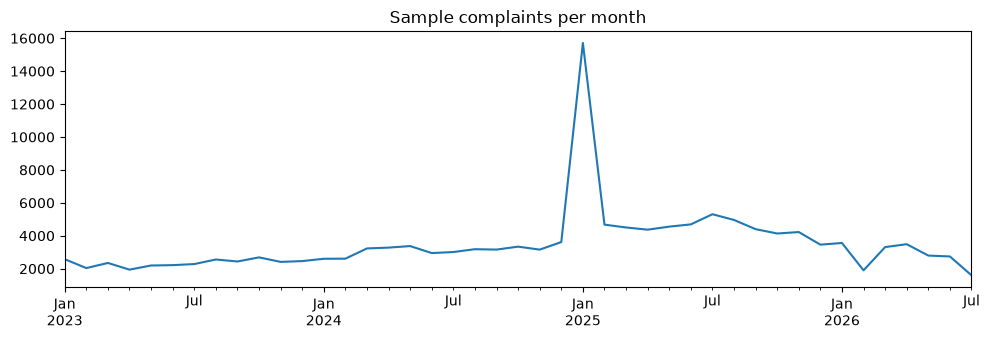

In [10]:
monthly = df.groupby(df["date_received"].dt.to_period("M")).size()
display(monthly.tail(12).rename("complaints").to_frame())
ax = monthly.plot(figsize=(10, 3.5), title="Sample complaints per month")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 6. Narrative text quality

**What this does:** measures how long each complaint narrative is, in characters and in words, and prints the spread
(percentiles: for example the 95th percentile is the length that 95% of narratives are shorter than). Missing narratives count as empty text.

In [11]:
text = df["narrative"].fillna("")
chars = text.str.len()
words = text.str.split().str.len()
print("characters per narrative:")
display(chars.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(0).to_frame("chars"))
print(f"median words: {int(words.median())} | 95th percentile words: {int(words.quantile(0.95))}")

characters per narrative:


,chars
count,150000.0
mean,1135.0
std,1341.0
min,50.0
5%,144.0
25%,413.0
50%,741.0
75%,1410.0
95%,3203.0
99%,6056.0


median words: 131 | 95th percentile words: 549


**What this does:** checks for very short narratives and for the masked `XXXX` placeholders that the CFPB uses to hide personal details.

In [12]:
print(f"narratives under 100 characters: {(chars < 100).mean() * 100:.1f}%")
print(f"narratives containing masked 'XXXX' placeholders: {text.str.contains('XXXX', regex=False).mean() * 100:.1f}%")

narratives under 100 characters: 2.2%
narratives containing masked 'XXXX' placeholders: 69.4%


**What this does:** finds narratives that appear more than once (copy/paste or templates) and shows the 5 most repeated
(first 120 characters only). `keep=False` marks every copy, not just the later ones.

In [13]:
dup_text = text.duplicated(keep=False)
print(f"narratives that appear more than once (copy/paste or templates): {dup_text.sum():,} rows")
if dup_text.any():
    display(text[dup_text].str.slice(0, 120).value_counts().head(5).to_frame("count"))

narratives that appear more than once (copy/paste or templates): 21,872 rows


,count
narrative,
"I am filing a complaint against Cash App ( Block , Inc. ) due to inadequate customer service and unfair practices, which",3207
"I am writing to formally express my concerns regarding Zelle 's handling of disputes, particularly in light of the recen",1329
There are collection accounts on my report that I believe contain inaccurate information. Under my rights pursuant to 15,733
I am writing to file a complaint against Navy Federal Credit Union regarding multiple overdraft fees I have incurred. De,525
I want to stress that I did not give written permission for these specific transactions to be included in my consumer re,504


## 7. Who complains, and where
The company tables were removed on purpose: `company` is dropped in this notebook. Only the state table is kept.

**What this does:** shows the 10 states with the most complaints.

In [14]:
display(df["state"].value_counts().head(10).to_frame("n"))

,n
state,
TX,17752
CA,16924
FL,15384
GA,9409
NY,8739
IL,7353
PA,5329
NC,5143
NJ,4638


## 8. Candidate target: did the consumer get relief?  *(paste this back)*
We treat a complaint as **relief** if the company response mentions relief (monetary or non-monetary).
Rows still "In progress" or marked "Untimely response" have no final outcome, so they are excluded from this target.

**What this does:** adds two columns. `target_eligible` is True when the response is a final one (not "in progress" or "untimely"),
and `got_relief` is 1 when the response text contains the word "relief". Then it keeps only the eligible rows in `elig`
and prints how many there are and the overall relief rate.

In [15]:
resp_text = df["company_response"].fillna("")
no_final_outcome = resp_text.str.contains("in progress|untimely", case=False, regex=True)
df["target_eligible"] = ~no_final_outcome
df["got_relief"] = resp_text.str.contains("relief", case=False).astype(int)

elig = df[df["target_eligible"]]
print(f"eligible rows: {len(elig):,} of {len(df):,} ({len(elig) / len(df) * 100:.1f}%)")
print(f"overall relief rate: {elig['got_relief'].mean() * 100:.2f}%")

eligible rows: 148,767 of 150,000 (99.2%)
overall relief rate: 22.63%


**What this does:** for each product group, shows the number of eligible complaints and the relief rate in percent,
largest groups first.

In [16]:
by_prod = elig.groupby("product_group")["got_relief"].agg(n="size", relief_rate="mean")
by_prod["relief_rate"] = (by_prod["relief_rate"] * 100).round(2)
by_prod = by_prod.sort_values("n", ascending=False)
display(by_prod)

,n,relief_rate
product_group,,
Credit reporting,24988,47.18
Bank account,24978,18.54
Credit or prepaid card,24968,32.22
Debt collection,24786,24.40
Money transfer / virtual currency,20353,6.81
Mortgage,10091,4.74
Vehicle loan or lease,7057,8.43
Student loan,5693,3.90
Payday / personal loan,4683,6.96


**What this does:** plots the relief rate for each month. If the line drifts over time, the target is not stable and needs care.

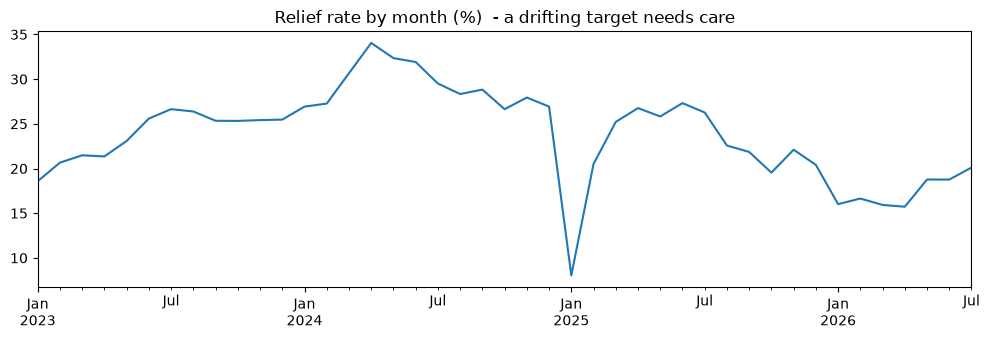

In [17]:
by_month = elig.groupby(elig["date_received"].dt.to_period("M"))["got_relief"].mean() * 100
ax = by_month.plot(figsize=(10, 3.5), title="Relief rate by month (%)  - a drifting target needs care")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 9. Proposed time-based split
Split by **date**, not randomly, so the test set is genuinely "the future". Cutoffs are rounded to month starts.
The archive ends on 2026-08-14, so the final month is partial.

**What this does:** sorts the eligible complaint dates and picks the date at the 70% and 85% positions as cutoffs,
rounded down to the first day of that month. Before the first cutoff is train, between the cutoffs is validation, after is test.

In [18]:
sorted_dates = elig["date_received"].sort_values().reset_index(drop=True)
position_70 = int(len(sorted_dates) * 0.70)
position_85 = int(len(sorted_dates) * 0.85)
# to_period("M").to_timestamp() rounds a date down to the 1st of its month
cut_val = pd.Timestamp(sorted_dates.iloc[position_70]).to_period("M").to_timestamp()
cut_test = pd.Timestamp(sorted_dates.iloc[position_85]).to_period("M").to_timestamp()
print("validation starts:", cut_val.date(), "| test starts:", cut_test.date())

validation starts: 2025-07-01 | test starts: 2025-11-01


**What this does:** labels each eligible row train / validation / test using the cutoffs, then prints the size, date range
and relief rate of each part. `right=False` means a cutoff date itself belongs to the later part.

In [19]:
elig = elig.assign(
    split=pd.cut(
        elig["date_received"],
        bins=[pd.Timestamp.min, cut_val, cut_test, pd.Timestamp.max],
        labels=["train", "validation", "test"],
        right=False,
    )
)
summary = elig.groupby("split", observed=True).agg(
    rows=("complaint_id", "size"),
    first_date=("date_received", "min"),
    last_date=("date_received", "max"),
    relief_rate=("got_relief", "mean"),
)
summary["relief_rate"] = (summary["relief_rate"] * 100).round(2)
print(f"train < {cut_val.date()} <= validation < {cut_test.date()} <= test")
display(summary)

train < 2025-07-01 <= validation < 2025-11-01 <= test


,rows,first_date,last_date,relief_rate
split,,,,
train,103778,2023-01-01,2025-06-30,23.70
validation,18537,2025-07-01,2025-10-31,22.78
test,26452,2025-11-01,2026-07-29,18.34


## 10. Save the audit summary
This small JSON goes into `reports/data_quality/` and feeds the model card later.

**What this does:** collects the key numbers from this notebook into one dictionary and writes it to
`reports/data_quality/audit_summary.json`, then closes the database connection. *JSON* is a simple text format for saving such dictionaries.

In [20]:
audit = {
    "rows": int(len(df)),
    "unique_complaint_ids": int(n_unique_ids),
    "date_min": str(df["date_received"].min().date()),
    "date_max": str(df["date_received"].max().date()),
    "product_groups": prod.set_index("product_group")["n"].astype(int).to_dict(),
    "company_response_counts": resp.set_index("company_response")["n"].astype(int).to_dict(),
    "target_eligible_rows": int(len(elig)),
    "relief_rate_pct": round(float(elig["got_relief"].mean() * 100), 2),
    "narrative_median_chars": int(chars.median()),
    "pct_with_xxxx": round(float(text.str.contains("XXXX", regex=False).mean() * 100), 1),
    "proposed_split": {"validation_starts": str(cut_val.date()), "test_starts": str(cut_test.date())},
}
out = REPORT_DIR / "audit_summary.json"
out.write_text(json.dumps(audit, indent=2, default=str))
print("saved", out.resolve())
con.close()

saved D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\reports\data_quality\audit_summary.json
